# Cross-Sectional Machine Learning & Event-Driven Backtesting on the B3 (IBrX 50)

**Author:** Pedro Magalhães  
**Universe:** 41 High-Liquidity Brazilian Equities (IBrX 50, 2012–2025)  
**Models Evaluated:** L2 Regularized Linear Regression (**Ridge Baseline**), **XGBoost**, and **LightGBM**  
**Simulation Protocol:** Event-Driven Execution at $t+1$ Adjusted Open · `15 bps` Transaction Cost · Top-10 Ranking with Top-20 Hysteresis Buffer

---

## 1. Environment & Universe Overview
This notebook demonstrates the complete Quantitative Machine Learning pipeline:
1. **Strictly Causal Feature Engineering ($\le t$)**: 12 momentum, mean-reversion, volatility, and volume indicators standardized cross-sectionally via per-day Z-scores.
2. **Purged Chronological Split (70% / 20% / 10%)**: 21-trading-day embargo at partition boundaries to eliminate forward-return leakage.
3. **Multi-Metric Evaluation**: Regression ($RMSE$, $MAE$), Ranking ($IC$, Spearman $Rank\ IC$, Top-10 Spread in bps), and Directional Classification ($AUC\text{-}ROC$, $F1$).
4. **Realistic Event-Driven Backtesting**: Out-of-Sample Frozen Test (`Nov/2024–Dec/2025`) vs. 11-Year Walk-Forward Retraining (`2015–2025`).

In [1]:
import sys
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

ROOT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT_DIR / "src"))

from quant_ml_b3 import (
    FEATURE_COLS,
    load_local_market_data,
    build_ml_panel,
    split_temporal_70_20_10,
)

market = load_local_market_data(ROOT_DIR / "data" / "processed")
print(f"Loaded {len(market.tickers)} B3 stocks across {len(market.dates)} trading days ({market.dates[0].date()} to {market.dates[-1].date()})")
print("Tickers:", ", ".join(market.tickers))

Loaded 41 B3 stocks across 3630 trading days (2012-01-02 to 2026-09-04)
Tickers: VALE3, ITUB4, PETR4, PETR3, BBDC4, SBSP3, B3SA3, ITSA4, WEGE3, ABEV3, BBAS3, BPAC11, EQTL3, RENT3, RDOR3, SUZB3, PRIO3, ENEV3, BBSE3, RAIL3, VBBR3, VIVT3, GGBR4, TOTS3, RADL3, CMIG4, LREN3, UGPA3, TIMS3, ENGI11, ASAI3, KLBN11, MOTV3, HAPV3, HYPE3, CSAN3, BRAV3, MULT3, CYRE3, CSNA3, MGLU3


## 2. Purged Chronological Split (70% Train / 20% Validation / 10% Test)
To predict 21-day forward excess returns without *look-ahead bias*, a 21-day purge (embargo) removes observations near the `Train -> Validation` and `Validation -> Test` boundaries whose forward target windows would otherwise cross into the next partition.

In [2]:
market_15_25 = market.slice_dates("2015-01-02", "2025-12-31")
panel = build_ml_panel(market_15_25, horizon=21, step=5)
splits = split_temporal_70_20_10(panel, train_ratio=0.70, val_ratio=0.20, purge_days=21)

summary_splits = pd.DataFrame([
    {"Partition": "1. Train (70%)", "Start": splits.meta["train_period"][0].date(), "End": splits.meta["train_period"][1].date(), "Rebalance Dates": splits.meta["n_dates_train"], "Samples (Date x Stock)": len(splits.train)},
    {"Partition": "2. Validation (20% - Purged 21d)", "Start": splits.meta["val_period"][0].date(), "End": splits.meta["val_period"][1].date(), "Rebalance Dates": splits.meta["n_dates_val"], "Samples (Date x Stock)": len(splits.val)},
    {"Partition": "3. Pure Test (10% - Purged 21d)", "Start": splits.meta["test_period"][0].date(), "End": splits.meta["test_period"][1].date(), "Rebalance Dates": splits.meta["n_dates_test"], "Samples (Date x Stock)": len(splits.test)},
])
display(summary_splits)

,Partition,Start,End,Rebalance Dates,Samples (Date x Stock)
0,1. Train (70%),2015-04-07,2022-08-23,366,13265
1,2. Validation (20% - Purged 21d),2022-09-28,2024-10-04,102,4063
2,3. Pure Test (10% - Purged 21d),2024-11-08,2025-11-26,53,2171


## 3. Data Science Evaluation: Statistical & Ranking Metrics (70 / 20 / 10)
Below are the out-of-sample regression, cross-sectional ranking ($IC$ and $Rank\ IC$), and directional classification ($AUC\text{-}ROC$, $F1$) metrics across the three architectures.

In [3]:
ml_metrics = pd.read_csv(ROOT_DIR / "outputs" / "tables" / "ml_metrics_70_20_10.csv")
display(ml_metrics)

,Modelo,Particao,n_obs,RMSE,MAE,R2_pct,IC_Pearson,Rank_IC_Spearman,Acuracia_Direcional_pct,AUC_ROC,F1_Score,Spread_Top10_bps,Win_Periodos_Top10_pct
0,RIDGE,1. Treino (70%),13265,0.0989,0.0693,1.09,0.1045,0.0582,52.83,0.5316,0.4657,154.8,61.2
1,RIDGE,2. Validacao (20%),4063,0.0799,0.0582,-2.98,-0.0574,-0.0470,48.14,0.4820,0.4410,-50.2,39.2
2,RIDGE,3. Teste (10%),2171,0.0883,0.0634,-2.10,-0.0348,-0.0175,47.95,0.4861,0.4350,-9.8,50.9
3,XGBOOST,1. Treino (70%),13265,0.0980,0.0688,2.95,0.1908,0.1047,54.55,0.5547,0.4545,202.1,66.7
4,XGBOOST,2. Validacao (20%),4063,0.0798,0.0580,-2.60,-0.0138,-0.0182,50.14,0.4973,0.4185,-16.3,41.2
5,XGBOOST,3. Teste (10%),2171,0.0886,0.0638,-2.77,-0.0389,-0.0220,46.71,0.4866,0.3783,-57.0,49.1
6,LIGHTGBM,1. Treino (70%),13265,0.0955,0.0674,7.71,0.3412,0.2166,57.69,0.6028,0.4901,340.3,80.1
7,LIGHTGBM,2. Validacao (20%),4063,0.0800,0.0582,-3.28,0.0004,-0.0099,49.94,0.4985,0.4162,-11.9,46.1
8,LIGHTGBM,3. Teste (10%),2171,0.0890,0.0639,-3.87,-0.0267,-0.0052,48.13,0.5003,0.3953,-75.8,35.8


## 4. Feature Importance Analysis Across Architectures
Comparing tree-based relative Gain (**XGBoost** and **LightGBM**) with standardized linear coefficients (**Ridge**):

,Feature,Ridge_Abs_Beta,Ridge_Beta,XGBoost_Gain,LightGBM_Gain
0,vol_21d,0.00887,0.00887,0.30606,0.16877
1,sma_ratio,0.00080,-0.00080,0.11784,0.12265
2,ret_63d,0.00060,-0.00060,0.11679,0.11057
3,ret_10d,0.00411,0.00411,0.09390,0.08160
4,ret_1d,0.00213,-0.00213,0.09329,0.08768
5,bb_pos,0.00527,-0.00527,0.07355,0.08550
6,sma50_dist,0.00028,-0.00028,0.07350,0.08078
7,ret_21d,0.00388,0.00388,0.04831,0.06676
8,vol_ratio,0.00016,0.00016,0.02861,0.06711
9,ret_5d,0.00222,0.00222,0.01680,0.04497


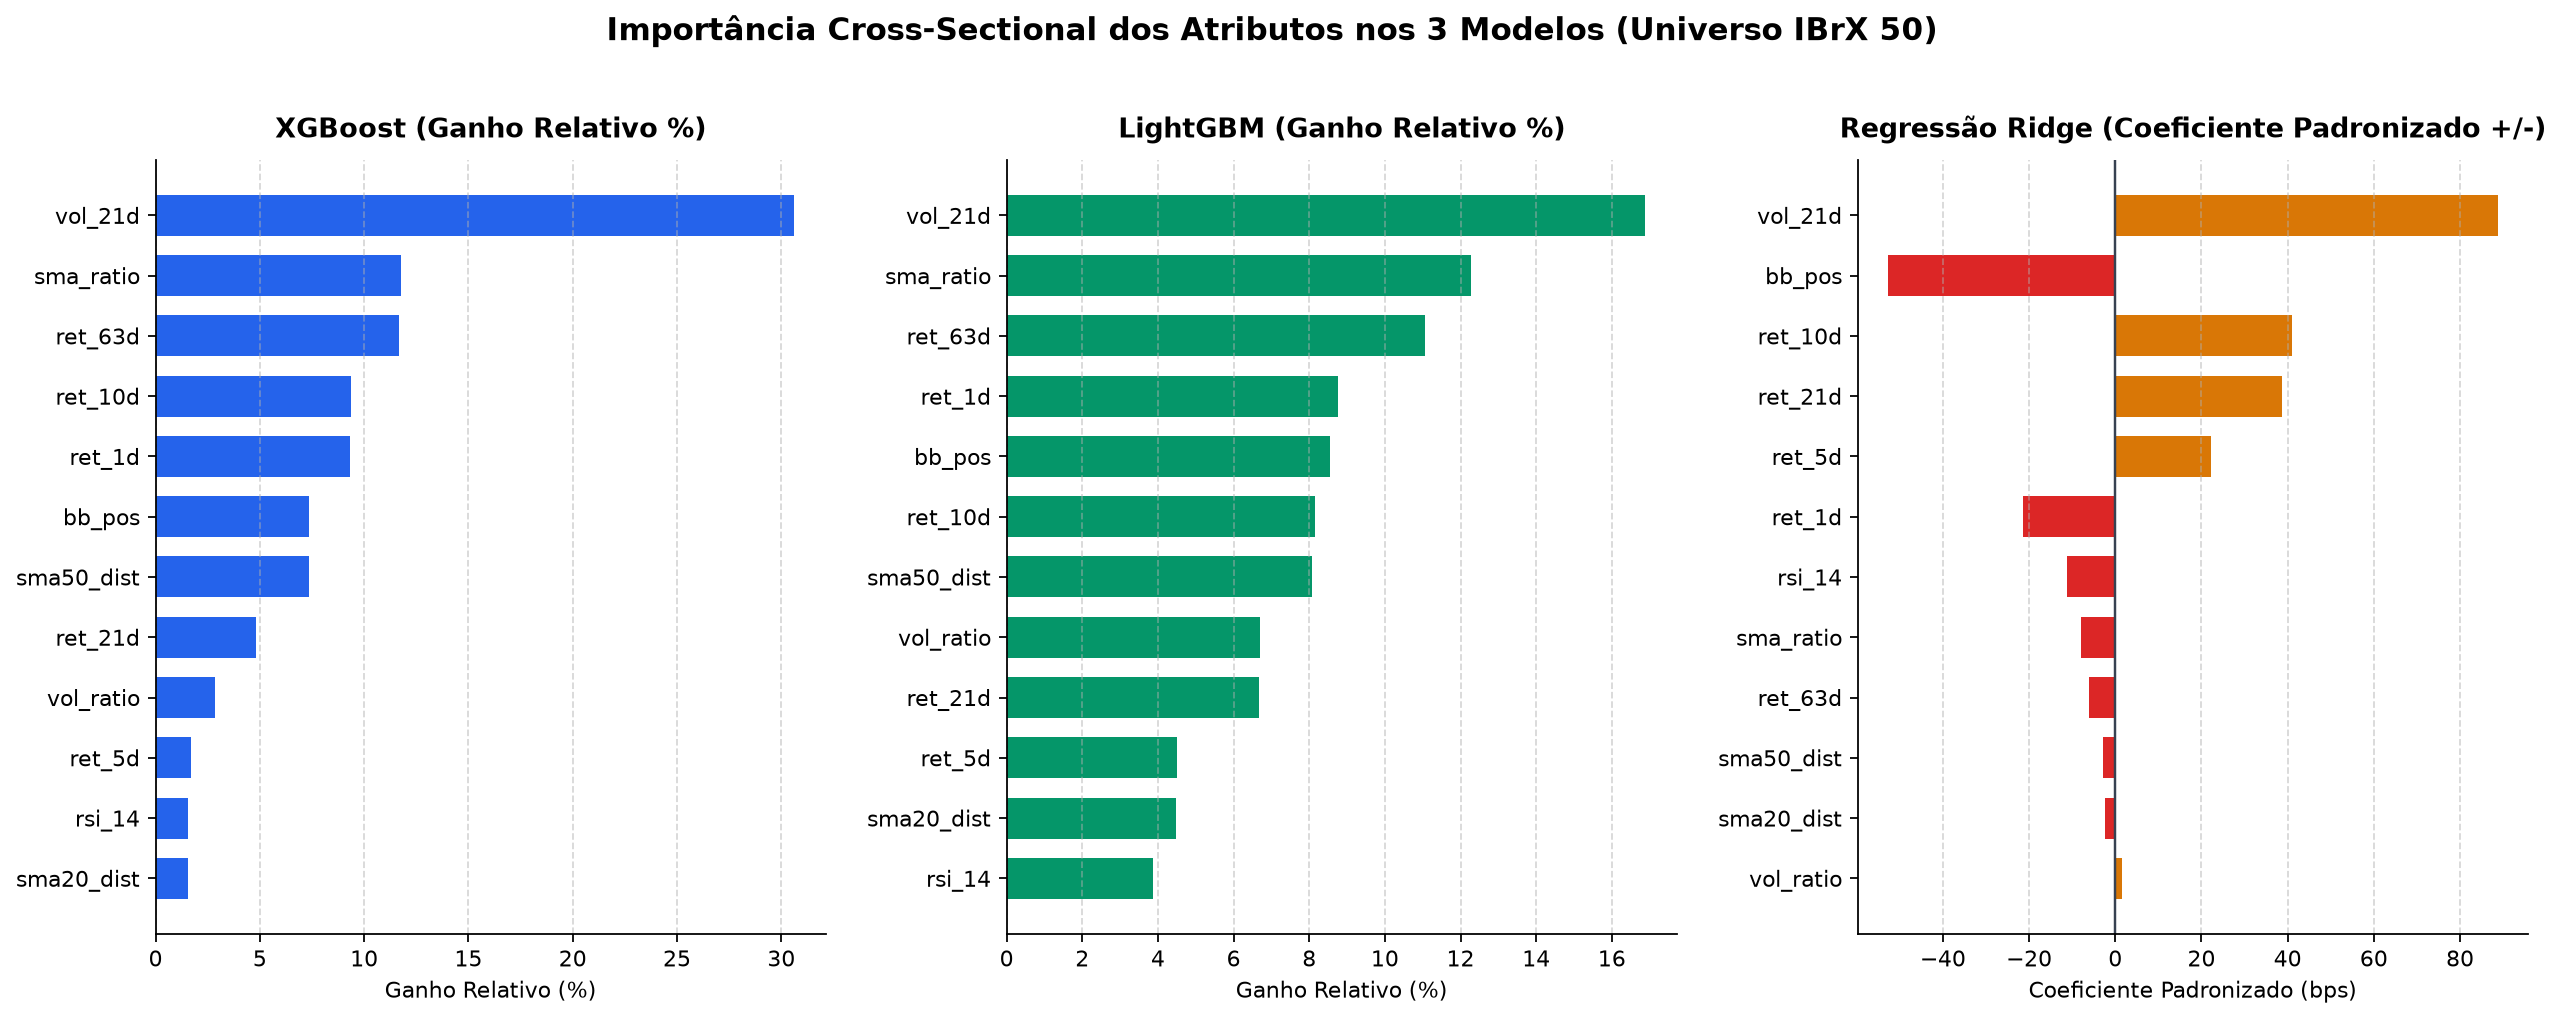

In [4]:
imp_df = pd.read_csv(ROOT_DIR / "outputs" / "tables" / "feature_importance.csv")
display(imp_df)
display(Image(filename=str(ROOT_DIR / "outputs" / "figures" / "01_feature_importance.png")))

## 5. Event-Driven Portfolio Backtesting (Net of `15 bps` Transaction Costs)
We compare two empirical regimes starting with **R$ 100,000.00**:
1. **Pure Out-of-Sample Test (10%: Nov/2024 – Dec/2025)**: Models are frozen after training prior to the test window.
2. **Full Walk-Forward Simulation (2015 – 2025)**: Models are periodically retrained every 12 months on a rolling 3-year window (`756` trading days), rebalanced monthly into the Top 10 predicted stocks with a Top 20 maintenance buffer.

In [5]:
df_oos = pd.read_csv(ROOT_DIR / "outputs" / "tables" / "backtest_oos_test10pct.csv")
df_wf = pd.read_csv(ROOT_DIR / "outputs" / "tables" / "backtest_walkforward_2015_2025.csv")

print("=== A) PURE OUT-OF-SAMPLE TEST (10%: NOV/2024 - DEC/2025) ===")
display(df_oos[["strategy", "final_equity", "net_profit_brl", "total_return", "annual_return", "sharpe", "max_drawdown", "win_rate"]])

print("\n=== B) FULL 11-YEAR WALK-FORWARD BACKTEST (2015 - 2025) ===")
display(df_wf[["strategy", "final_equity", "net_profit_brl", "total_return", "annual_return", "sharpe", "max_drawdown", "calmar", "win_rate"]])

=== A) PURE OUT-OF-SAMPLE TEST (10%: NOV/2024 - DEC/2025) ===


,strategy,final_equity,net_profit_brl,total_return,annual_return,sharpe,max_drawdown,win_rate
0,Buy & Hold 1/N (IBrX 50),118139.35,18139.35,0.181393,0.160628,0.855839,-0.125810,NaN
1,ML Baseline: Regressao Ridge,136091.26,36091.26,0.360913,0.317022,1.656547,-0.113788,0.753247
2,ML: XGBoost,116018.73,16018.73,0.160187,0.141993,0.665617,-0.129589,0.695122
3,ML: LightGBM,104253.18,4253.18,0.042532,0.037923,0.192690,-0.123548,0.651163



=== B) FULL 11-YEAR WALK-FORWARD BACKTEST (2015 - 2025) ===


,strategy,final_equity,net_profit_brl,total_return,annual_return,sharpe,max_drawdown,calmar,win_rate
0,Buy & Hold 1/N (IBrX 50),770108.20,670108.20,6.701082,0.207690,0.746503,-0.486334,0.427053,NaN
1,ML Baseline: Regressao Ridge,982755.93,882755.93,8.827559,0.235221,0.862565,-0.486309,0.483687,0.694245
2,ML: XGBoost,902867.59,802867.59,8.028676,0.225578,0.801892,-0.447044,0.504599,0.655814
3,ML: LightGBM,984795.00,884795.00,8.847950,0.235458,0.832350,-0.509310,0.462308,0.677273
4,BRAX11 (Indice Passivo),340737.01,240737.01,2.407370,0.120001,0.514377,-0.475591,0.252320,NaN


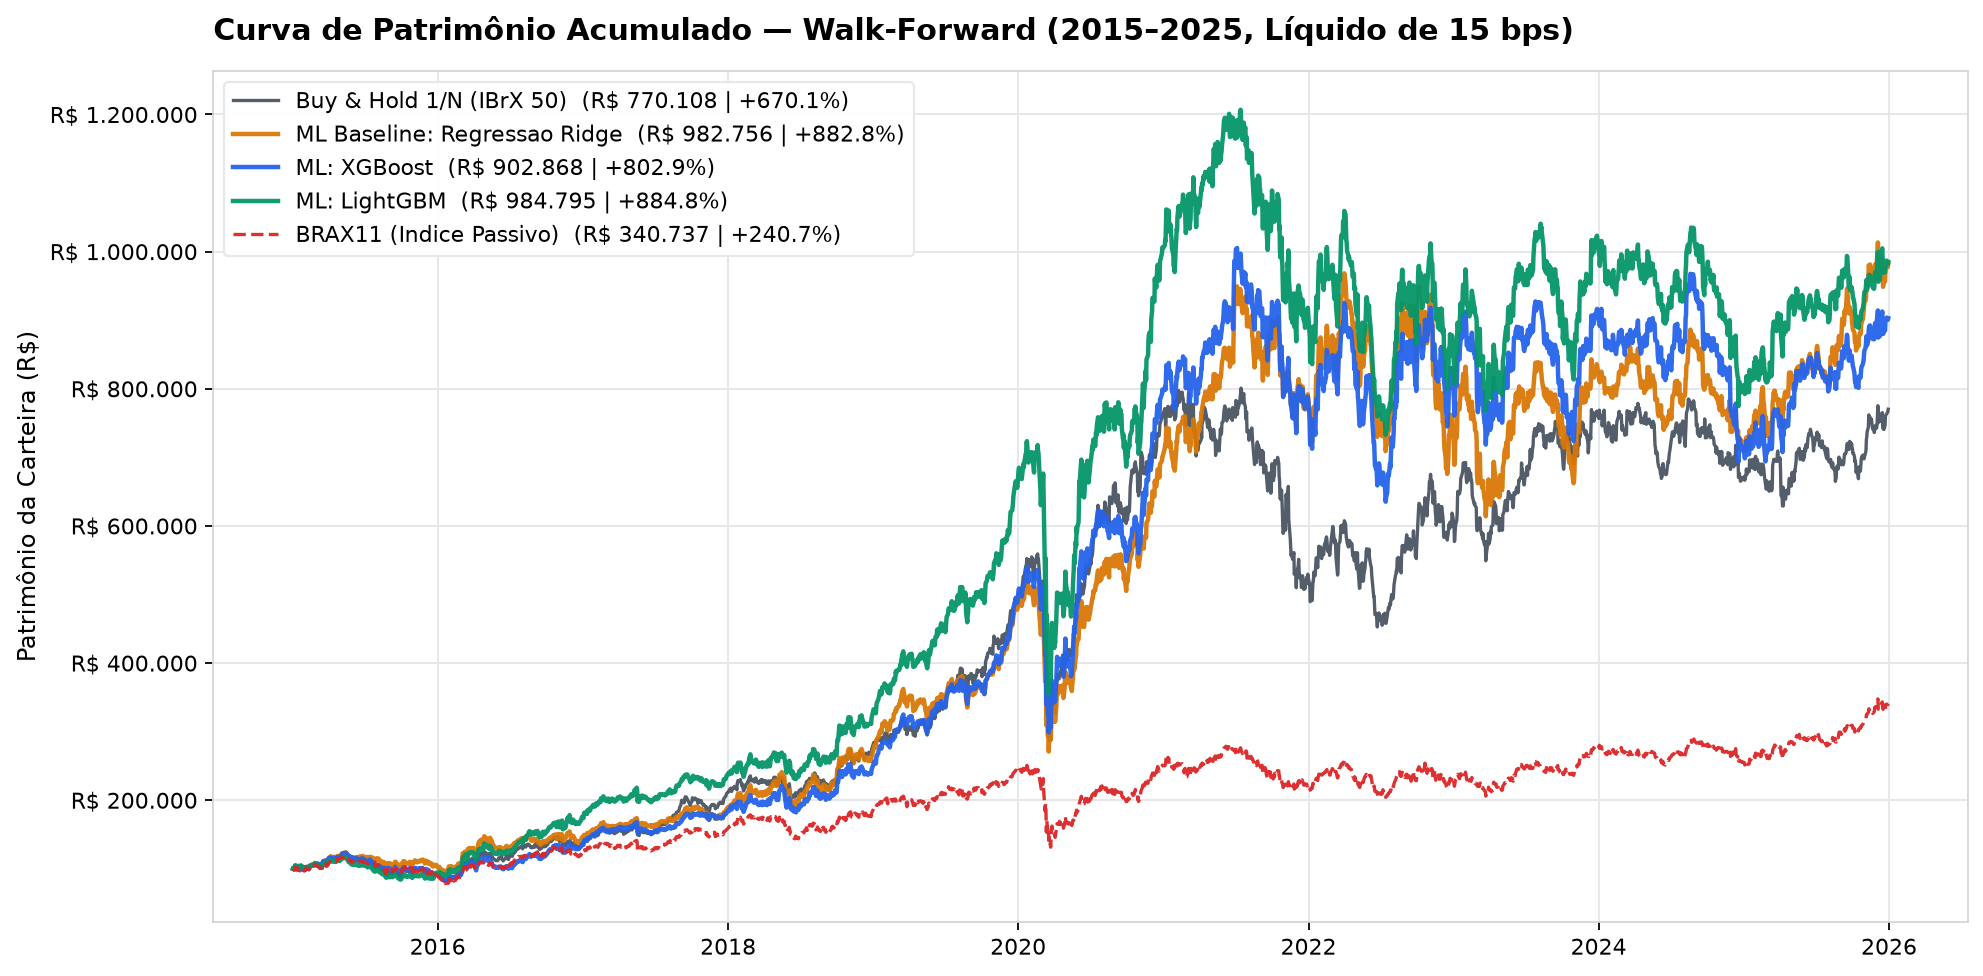

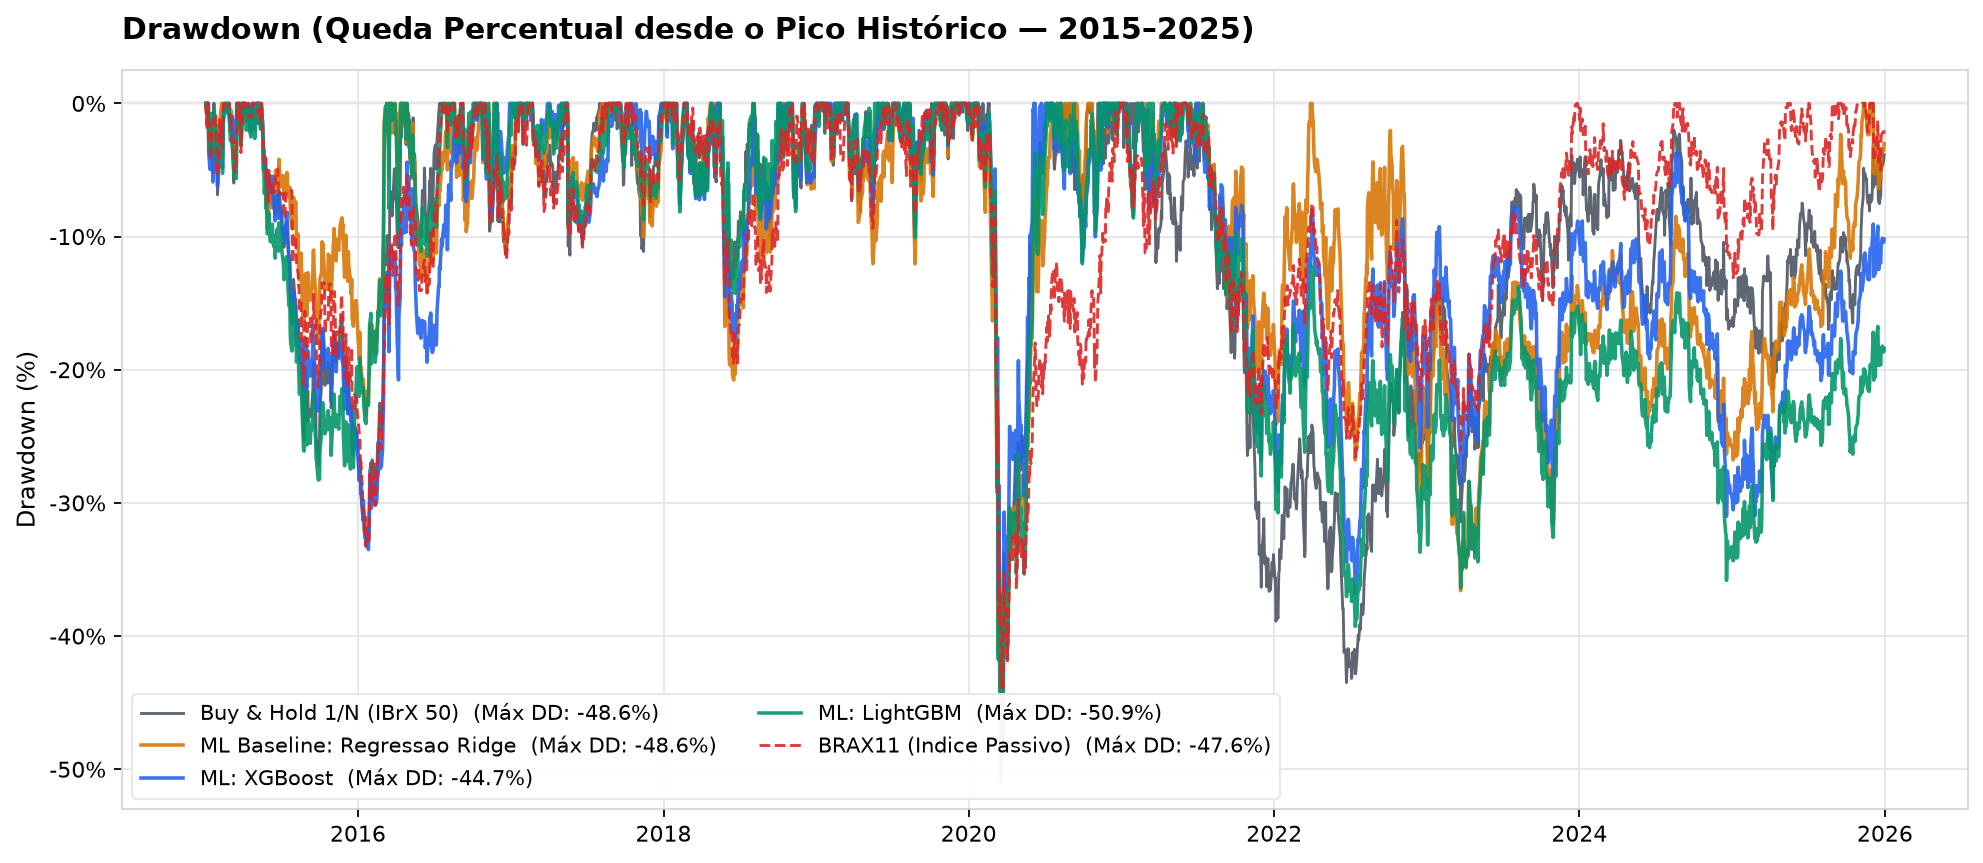

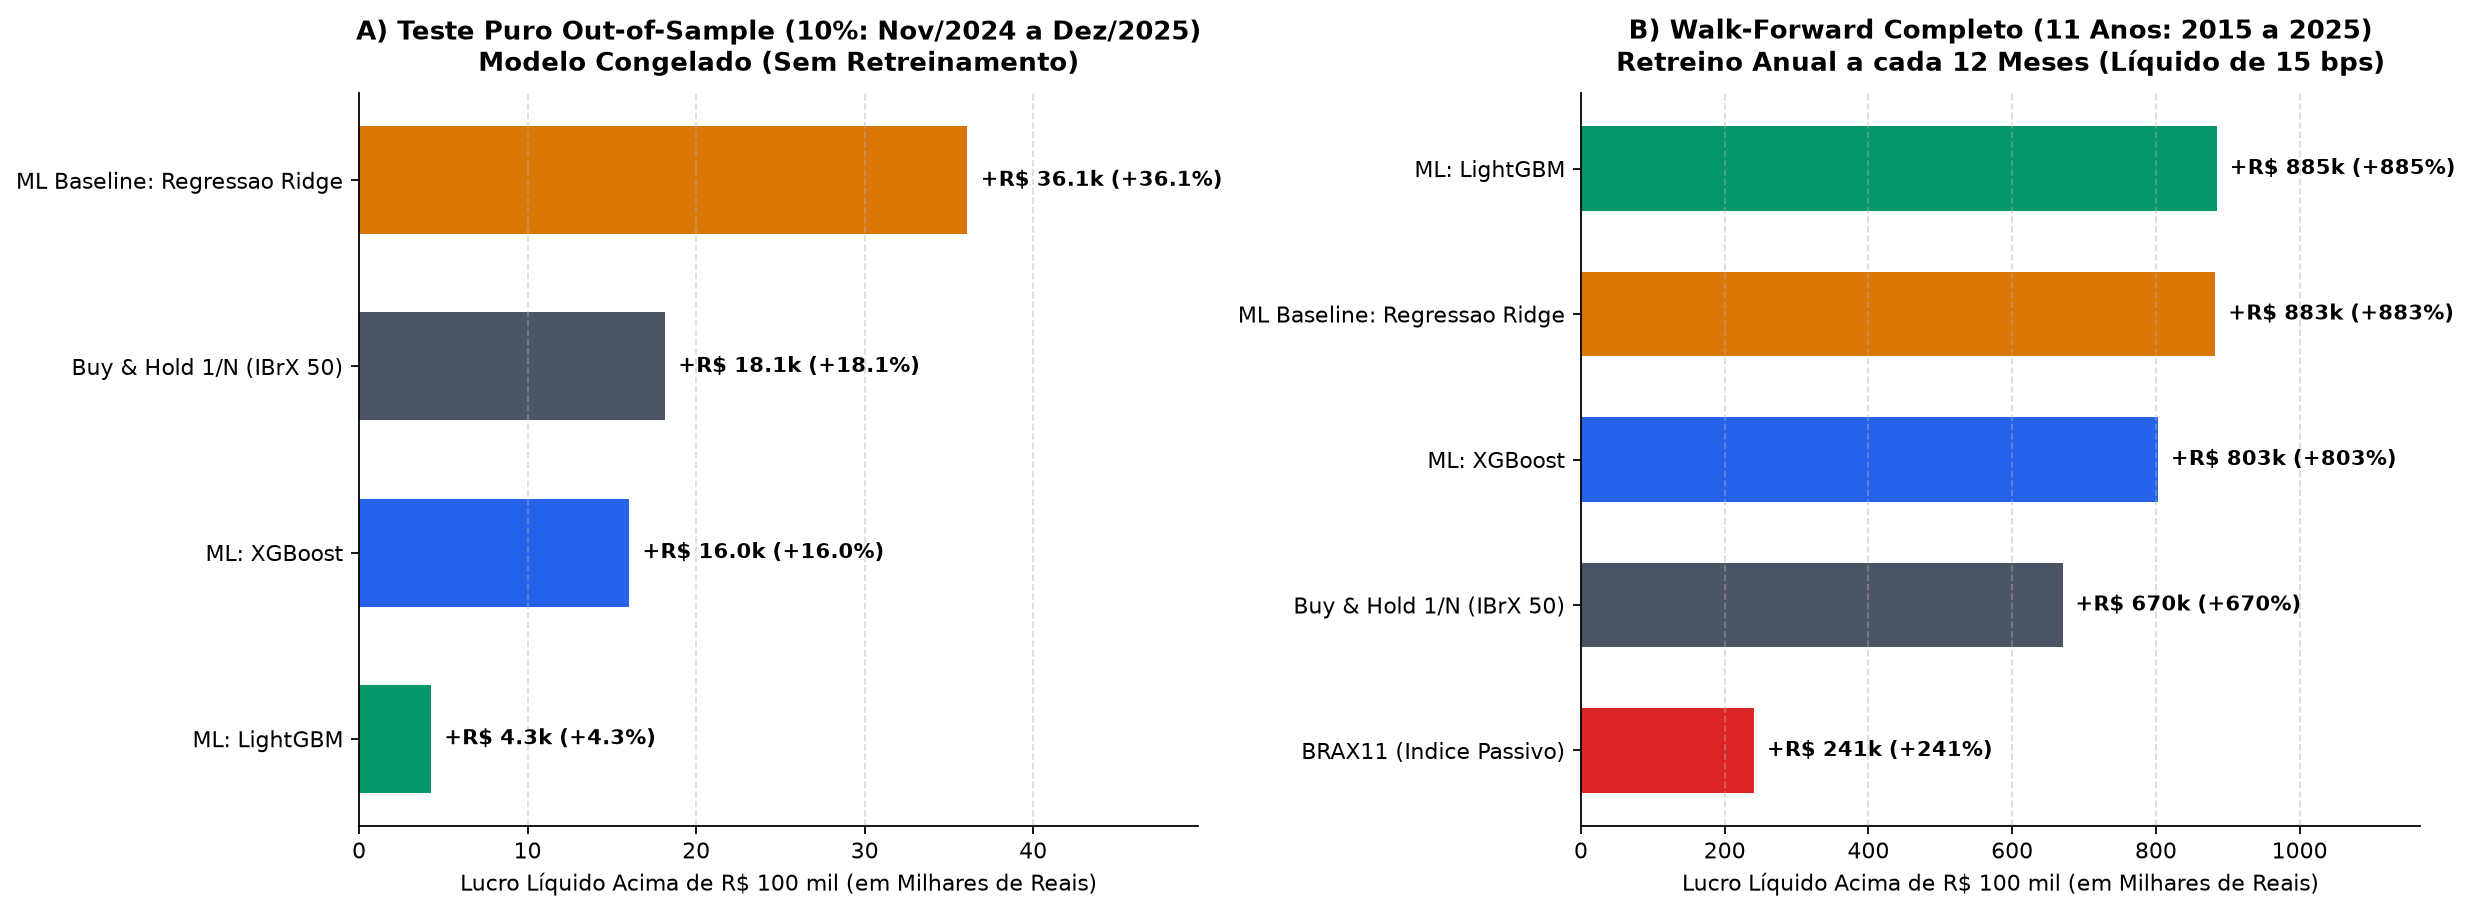

In [6]:
display(Image(filename=str(ROOT_DIR / "outputs" / "figures" / "02_walkforward_equity.png")))
display(Image(filename=str(ROOT_DIR / "outputs" / "figures" / "03_walkforward_drawdown.png")))
display(Image(filename=str(ROOT_DIR / "outputs" / "figures" / "04_oos_vs_walkforward_profit.png")))